> **Trainierte Modelle:** Dieses Notebook lädt das fertige Modell aus `models/` und trainiert nicht neu. Zum Neutrainieren in den Parametern `TRAIN_MODEL = True` setzen.

## 💭 Ausgangspunkt: die Frage, die diese Version beantwortet

**Beobachtung nach v4:** Die Rekonstruktionen wurden besser, zeigen aber starke fraktalartige Muster und wirken weiterhin unscharf.

**Status dieses Notebooks: vollständig ausgeführt** auf der CPU, in einem frischen Kernel, mit 1.500 Trainingsschritten. Die Vergleichsläufe stammen aus `v5_experiments/`, Skript und Ergebnisse liegen dort.

---

## 📝 Changelog: v5 gegenüber v4

| # | Einstellung | v4 | v5 | Warum |
|---|---|---|---|---|
| 1 | Upsampling | `Conv2DTranspose` | **`UpSampling2D` + `Conv2D`** | Ungleichmäßige Überlappung erzeugt ein Raster |
| 2 | Engpass | `Flatten` + `Dense` bei 2×2 | **räumlich, 8×8×`LATENT_CHANNELS`** | Erhält die Ortsinformation |
| 3 | `EMBEDDING_DIM` | 256 | **512** | Lauf R3 war sichtbar besser als R1 mit 256 |
| 4 | Blöcke | eine Conv je Stufe | **Residual-Blöcke** | Mehr Kapazität für Details |
| 5 | Normalisierung | `BatchNormalization` | **`GroupNormalization`** | Kein Unterschied zwischen Training und Inferenz |
| 6 | Loss | MSE + VGG-Feature-MSE | **L1 + `SSIM_WEIGHT` × (1 − SSIM)** | Kein Netz, das Raster übersehen kann, und viel günstiger |
| 7 | Daten | 10.000 Bilder, 15 Epochen | **30.000 Bilder, 5 Epochen, Flips** | Gleich viele Schritte (1.500), mehr Vielfalt |
| 8 | Lernrate | `ReduceLROnPlateau` | **Cosine** | Fester Plan bei kurzem Training |
| 9 | Validierung | `x_test[:2000]` | **letzte 5.000 Trainingsbilder** | Das Testset dient nur noch der Endauswertung |
| 10 | Auswertung | Laplace-Schärfe | **PSNR, SSIM, Spektrum, Nyquist, Zoom, Differenz** | Laplace belohnt Artefakte, siehe unten |
| 11 | Plot-Titel | fest „32-dim“ | **aus `EMBEDDING_DIM`** | Falsche Beschriftung behoben |

**Abweichungen vom Plan, wegen der CPU-Laufzeit:** Die Läufe nutzen 30.000 statt 45.000 Bilder. R2 war nur ein Nachtraining von 300 Schritten aus den R1-Gewichten, ohne VGG-Lauf von Grund auf. A1 und A2 sind zusätzlich dazugekommen, um Decoder und Loss zu trennen.

**Für einen vollständigen Lauf auf einer GPU:** `TRAIN_SAMPLES = 45000` und `EPOCHS = 25` setzen.

**Grenzen:**
- Die v4-Referenz R0 wurde mit dem v4-Code nachgestellt, weil vom ursprünglichen v4-Lauf weder Ausgaben noch Modelle gespeichert sind. Sie nutzt die letzten Trainingsbilder als Validierung statt Testbildern.
- Die neue Architektur wurde als Paket gemessen. Welchen Anteil Upsampling, Engpass, Residual-Blöcke und Normalisierung jeweils haben, ist nicht getrennt.
- Die PCA liegt bei gleicher Dimension rechnerisch noch vorn. Ob längeres Training das aufholt, ist offen.

# Autoencoder auf CIFAR-10

## Aufgabenbeschreibung

Wir haben gesehen, wie man einen Autoencoder für die Graustufenbilder des Fashion-MNIST-Datensatzes baut. In dieser Übung baust du einen für den CIFAR-10-Datensatz (https://www.cs.toronto.edu/~kriz/cifar.html). Dieser Datensatz enthält **Farbbilder** mit einer Auflösung von 32x32.

### Vorbereitung


In [1]:
import matplotlib.pyplot as plt


def sample_batch(dataset):
    batch = dataset.take(1).get_single_element()
    if isinstance(batch, tuple):
        batch = batch[0]
    return batch.numpy()


def display(
    images, n=10, size=(20, 3), cmap="gray_r", as_type="float32", save_to=None
):
    """
    Zeigt n Bilder aus jedem der übergebenen Arrays an.
    """
    if images.max() > 1.0:
        images = images / 255.0
    elif images.min() < 0.0:
        images = (images + 1.0) / 2.0

    plt.figure(figsize=size)
    for i in range(n):
        _ = plt.subplot(1, n, i + 1)
        plt.imshow(images[i].astype(as_type), cmap=cmap)
        plt.axis("off")

    if save_to:
        plt.savefig(save_to)
        print(f"\nSaved to {save_to}")

    plt.show()


In [2]:
%load_ext autoreload
%autoreload 2

import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import keras
import tensorflow as tf
from tensorflow.keras import layers, models, datasets, callbacks

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

from scipy.ndimage import convolve

I0000 00:00:1793541533.892523 1896673 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793541535.869665 1896673 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 0. Parameter <a name="parameters"></a>

In [3]:
IMAGE_SIZE = 32
CHANNELS = 3
BATCH_SIZE = 100

# Räumlicher Engpass: 8x8 x LATENT_CHANNELS. 8 Kanäle ergeben 512 Dimensionen (Lauf R3),
# 4 Kanäle ergeben 256 Dimensionen wie in v4 (Lauf R1).
LATENT_CHANNELS = 8
EMBEDDING_DIM = 8 * 8 * LATENT_CHANNELS
WIDTHS = (32, 64, 128)

# CPU-Budget: 1.500 Schritte wie in v4. Auf einer GPU TRAIN_SAMPLES = 45000 und EPOCHS = 25 setzen.
TRAIN_SAMPLES = 30000
VAL_SAMPLES = 5000
EPOCHS = 5

LEARNING_RATE = 1e-3
SSIM_WEIGHT = 0.2

# Eigene Modelle laden statt neu trainieren. True trainiert neu.
TRAIN_MODEL = False

## 1. Daten vorbereiten <a name="prepare"></a>

In [4]:
# Daten laden
(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

In [5]:
# Daten vorverarbeiten

def preprocess(imgs):
    """
    Normalisiert die Bilder und bringt sie in die richtige Form
    """
    imgs = imgs.astype("float32") / 255.0
    imgs = imgs.reshape(len(imgs),imgs.shape[1],imgs.shape[2],3)
    return imgs


x_train = preprocess(x_train)
x_test = preprocess(x_test)

In [6]:
# v5: Die Validierung kommt aus dem Trainingsset, das Testset dient nur der Endauswertung.
x_val = x_train[-VAL_SAMPLES:]
x_fit = x_train[:TRAIN_SAMPLES]

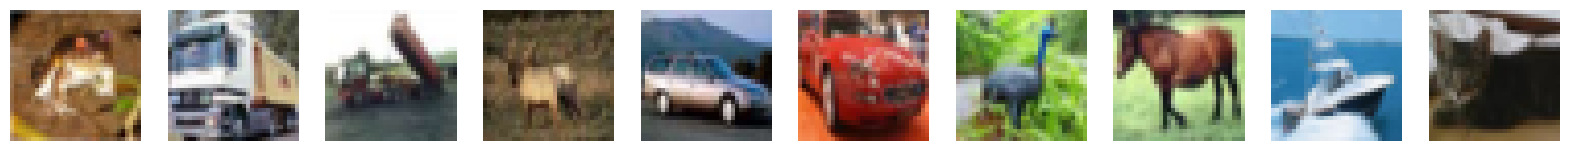

In [7]:
# Einige Bilder aus dem Trainingsset anzeigen
display(x_train)

## 2. Autoencoder aufbauen <a name="build"></a>

In [8]:
def res_block(x, filters):
    """Zwei Convs mit Skip innerhalb des Blocks, GroupNormalization statt BatchNormalization."""
    skip = x if x.shape[-1] == filters else layers.Conv2D(filters, 1)(x)
    y = layers.GroupNormalization(groups=8)(x)
    y = layers.Activation("relu")(y)
    y = layers.Conv2D(filters, 3, padding="same")(y)
    y = layers.GroupNormalization(groups=8)(y)
    y = layers.Activation("relu")(y)
    y = layers.Conv2D(filters, 3, padding="same")(y)
    return layers.Add()([skip, y])

In [9]:
# Encoder
# v5: bleibt räumlich bis 8x8, kein Flatten und kein Dense.
encoder_input = layers.Input(
    shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS), name="encoder_input"
)
x = layers.Conv2D(WIDTHS[0], 3, padding="same")(encoder_input)
x = res_block(x, WIDTHS[0])
x = layers.Conv2D(WIDTHS[1], 3, strides=2, padding="same")(x)
x = res_block(x, WIDTHS[1])
x = layers.Conv2D(WIDTHS[2], 3, strides=2, padding="same")(x)
x = res_block(x, WIDTHS[2])
x = layers.GroupNormalization(groups=8)(x)
x = layers.Activation("relu")(x)
encoder_output = layers.Conv2D(LATENT_CHANNELS, 1, name="encoder_output")(x)

encoder = models.Model(encoder_input, encoder_output, name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │        896 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalization │ (None, 32, 32,    │         64 │ conv2d[0][0]      │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ group_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_1[0][0]    │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 32, 32,    │          0 │ group_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │      9,248 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ conv2d[0][0],     │
│                     │ 32)               │            │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │     18,496 │ add[0][0]         │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 16, 16,    │        128 │ conv2d_3[0][0]    │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 16, 16,    │          0 │ group_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 16, 16,    │        128 │ conv2d_4[0][0]    │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 16, 16,    │          0 │ group_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16,    │     36,928 │ activation_3[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 16, 16,    │          0 │ conv2d_3[0][0], 

 Total params: 482,952 (1.84 MB)

 Trainable params: 482,952 (1.84 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# Decoder
# v5: UpSampling2D + Conv2D statt Conv2DTranspose, um Schachbrettmuster zu vermeiden.
# Bewusst keine Skips vom Encoder, sie würden den Engpass umgehen.
decoder_input = layers.Input(shape=encoder_output.shape[1:], name="decoder_input")
x = layers.Conv2D(WIDTHS[2], 3, padding="same")(decoder_input)
x = res_block(x, WIDTHS[2])
x = layers.UpSampling2D(2, interpolation="bilinear")(x)
x = layers.Conv2D(WIDTHS[1], 3, padding="same")(x)
x = res_block(x, WIDTHS[1])
x = layers.UpSampling2D(2, interpolation="bilinear")(x)
x = layers.Conv2D(WIDTHS[0], 3, padding="same")(x)
x = res_block(x, WIDTHS[0])
x = layers.GroupNormalization(groups=8)(x)
x = layers.Activation("relu")(x)
decoder_output = layers.Conv2D(
    CHANNELS, 3, activation="sigmoid", padding="same", name="decoder_output"
)(x)

decoder = models.Model(decoder_input, decoder_output, name="decoder")
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ decoder_input       │ (None, 8, 8, 8)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 8, 8, 128) │      9,344 │ decoder_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 8, 8, 128) │        256 │ conv2d_9[0][0]    │
│ (GroupNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_7        │ (None, 8, 8, 128) │          0 │ group_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 8, 8, 128) │    147,584 │ activation_7[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 8, 8, 128) │        256 │ conv2d_10[0][0]   │
│ (GroupNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 8, 8, 128) │          0 │ group_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 8, 8, 128) │    147,584 │ activation_8[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 8, 8, 128) │          0 │ conv2d_9[0][0],   │
│                     │                   │            │ conv2d_11[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 16, 16,    │          0 │ add_3[0][0]       │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 16, 16,    │     73,792 │ up_sampling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 16, 16,    │        128 │ conv2d_12[0][0]   │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 16, 16,    │          0 │ group_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 16, 16,    │     36,928 │ activation_9[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 16, 16,    │        128 │ conv2d_13[0][0]   │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_10       │ (None, 16, 16,    │          0 │ group_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 16, 16,    │     36,928 │ activation_10[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 16, 16,    │          0 │ conv2d_12[0][0],

 Total params: 490,947 (1.87 MB)

 Trainable params: 490,947 (1.87 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Autoencoder
autoencoder = models.Model(
    encoder_input, decoder(encoder_output), name="autoencoder"
)  # decoder(encoder_output)
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │        896 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalization │ (None, 32, 32,    │         64 │ conv2d[0][0]      │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ group_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 32, 32,    │         64 │ conv2d_1[0][0]    │
│ (GroupNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 32, 32,    │          0 │ group_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │      9,248 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ conv2d[0][0],     │
│                     │ 32)               │            │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │     18,496 │ add[0][0]         │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 16, 16,    │        128 │ conv2d_3[0][0]    │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 16, 16,    │          0 │ group_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 16, 16,    │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ group_normalizatio… │ (None, 16, 16,    │        128 │ conv2d_4[0][0]    │
│ (GroupNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 16, 16,    │          0 │ group_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 16, 16,    │     36,928 │ activation_3[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 16, 16,    │          0 │ conv2d_3[0][0], 

 Total params: 973,899 (3.72 MB)

 Trainable params: 973,899 (3.72 MB)

 Non-trainable params: 0 (0.00 B)

## 2a. Loss: L1 + SSIM

L1 bestraft Pixelabweichungen und neigt weniger zum Mitteln als MSE. SSIM vergleicht lokale Helligkeit, Kontrast und Struktur. Beide kommen ohne vortrainiertes Netz aus, das Hochfrequenzmuster übersehen könnte.

In [12]:
@keras.saving.register_keras_serializable(package="autoencoder_v5")
def l1_ssim_loss(y_true, y_pred):
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred), axis=[1, 2, 3])
    ssim = tf.image.ssim(y_true, y_pred, max_val=1.0, filter_size=7)
    return l1 + SSIM_WEIGHT * (1.0 - ssim)

## 3. Autoencoder trainieren <a name="train"></a>

In [13]:
# Autoencoder kompilieren
# v5: Cosine-Lernrate statt ReduceLROnPlateau.
steps_per_epoch = len(x_fit) // BATCH_SIZE
schedule = keras.optimizers.schedules.CosineDecay(
    LEARNING_RATE, steps_per_epoch * EPOCHS, alpha=0.01
)
autoencoder.compile(optimizer=keras.optimizers.Adam(schedule), loss=l1_ssim_loss)

In [14]:
# Checkpoint zum Speichern des Modells anlegen
model_checkpoint_callback = callbacks.ModelCheckpoint(
    filepath="./checkpoint_v5.keras",
    save_weights_only=False,
    save_freq="epoch",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=0,
)
tensorboard_callback = callbacks.TensorBoard(log_dir="./logs_v5")

In [15]:
if TRAIN_MODEL:
    # v5: horizontale Flips als Augmentierung.
    train_ds = (
        tf.data.Dataset.from_tensor_slices(x_fit)
        .shuffle(len(x_fit))
        .batch(BATCH_SIZE)
        .map(tf.image.random_flip_left_right, num_parallel_calls=tf.data.AUTOTUNE)
        .map(lambda batch: (batch, batch))
        .prefetch(tf.data.AUTOTUNE)
    )

    autoencoder.fit(
        train_ds,
        epochs=EPOCHS,
        validation_data=(x_val, x_val),
        validation_batch_size=BATCH_SIZE,
        callbacks=[model_checkpoint_callback, tensorboard_callback],
        verbose=2,
    )
else:
    autoencoder.set_weights(models.load_model("./models/autoencoder_v5.keras", compile=False).get_weights())

In [16]:
if TRAIN_MODEL:
    # Finale Modelle speichern
    Path("./models").mkdir(parents=True, exist_ok=True)
    autoencoder.save("./models/autoencoder_v5.keras")
    encoder.save("./models/encoder_v5.keras")
    decoder.save("./models/decoder_v5.keras")

## 4. Rekonstruieren mit dem Autoencoder <a name="reconstruct"></a>

In [17]:
n_to_predict = 5000
example_images = x_test[:n_to_predict]
example_labels = y_test[:n_to_predict]

Example real images


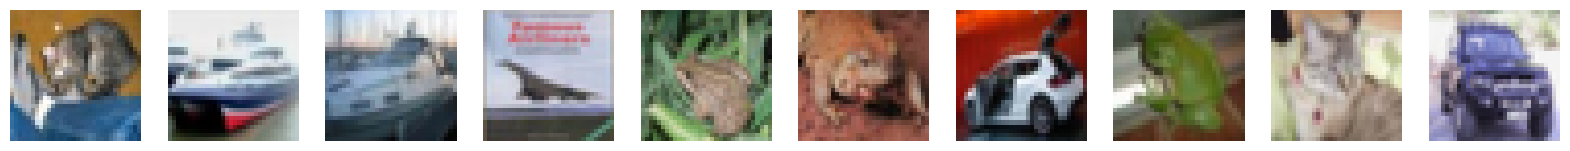

Reconstructions


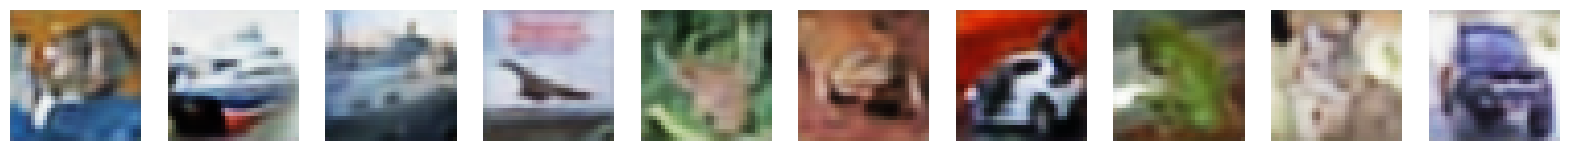

In [18]:
predictions = autoencoder.predict(x_test, batch_size=500, verbose=0)

print("Example real images")
display(x_test)
print("Reconstructions")
display(predictions)

### 4a. Muster sichtbar machen: Zoom und Differenz

Die Bilder sind 4-fach mit Nearest Neighbor vergrößert, damit kein Weichzeichnen der Anzeige Muster verdeckt. Obere Zeile Original, Mitte v5, darunter v3, unten die Differenz von v5 zum Original, 4-fach verstärkt.

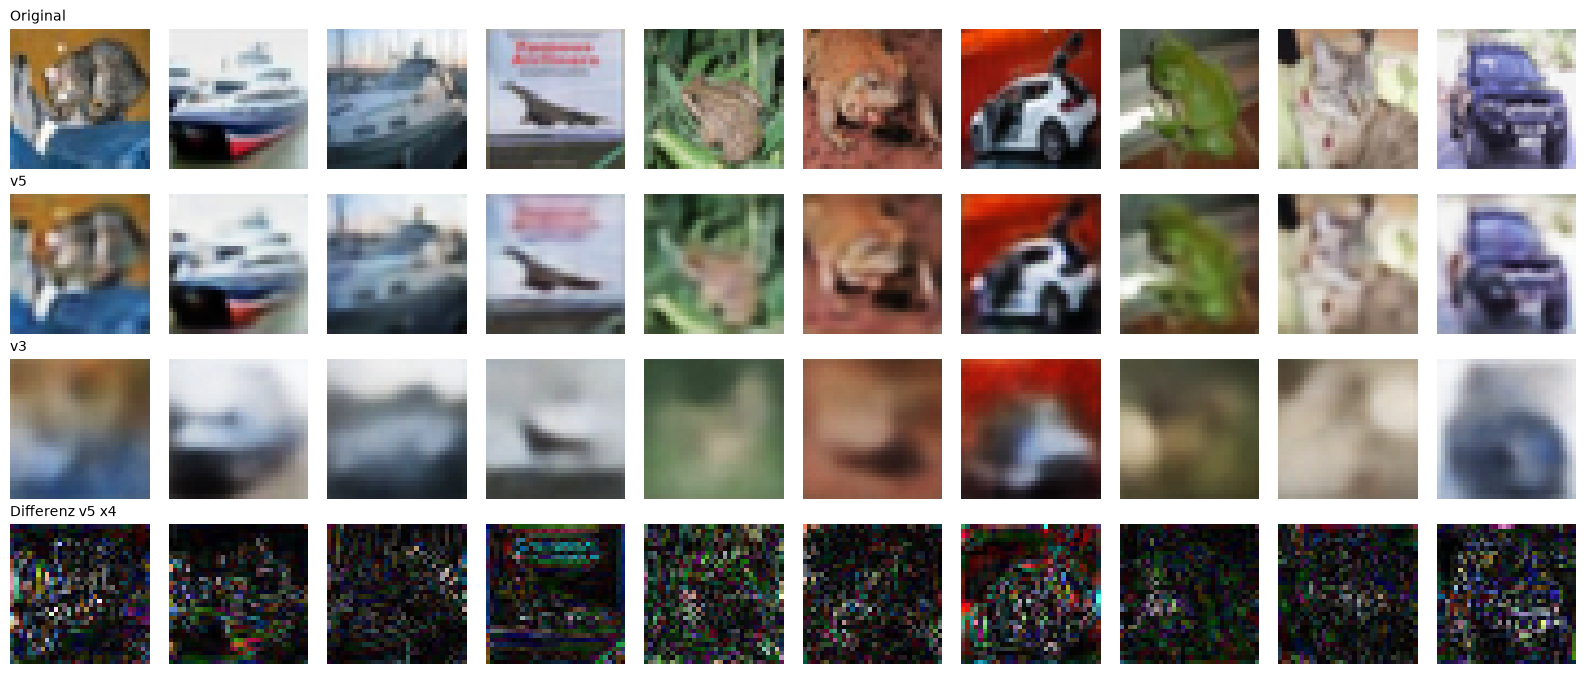

In [19]:
autoencoder_v3 = models.load_model("./models/autoencoder_v3.keras", compile=False)
predictions_v3 = autoencoder_v3.predict(x_test, batch_size=500, verbose=0)

rows = [
    ("Original", x_test),
    ("v5", predictions),
    ("v3", predictions_v3),
    ("Differenz v5 x4", np.clip(np.abs(x_test - predictions) * 4, 0, 1)),
]
n = 10
fig, axes = plt.subplots(len(rows), n, figsize=(n * 1.6, len(rows) * 1.7))
for r, (label, images) in enumerate(rows):
    for i in range(n):
        axes[r, i].imshow(np.kron(images[i], np.ones((4, 4, 1))), interpolation="nearest")
        axes[r, i].axis("off")
    axes[r, 0].set_title(label, loc="left", fontsize=10)
fig.tight_layout()
plt.show()

### 4b. Messen: PSNR, SSIM, Schärfe und Spektrum

- **PSNR und SSIM** messen die Treue zum Original.
- **Radiales Leistungsspektrum:** Liegt eine Kurve unter dem Original, fehlen Details. Eine Anhebung am rechten Ende spricht für Artefakte.
- **Nyquist-Leistung:** Leistung bei der höchsten Frequenz, wo ein Schachbrettmuster liegen würde.
- **Laplace-Schärfe nur mit Vorsicht lesen:** Auch Muster erhöhen sie. Allein belegt sie keine bessere Bildqualität.

Die Zeilen R0 bis R3 und die Basislinien stammen aus den Einzelläufen in `v5_experiments/runs/`. Die Zeile „v5 (dieses Notebook)“ wird hier neu gemessen und weicht wegen des zufälligen Starts leicht von R3 ab.

In [20]:
LUMA_WEIGHTS = np.array([0.299, 0.587, 0.114], dtype=np.float32)
LAPLACIAN_KERNEL = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32)


def radial_spectrum(images):
    luma = images @ LUMA_WEIGHTS
    luma = luma - luma.mean(axis=(1, 2), keepdims=True)
    power = (np.abs(np.fft.fftshift(np.fft.fft2(luma), axes=(1, 2))) ** 2).mean(axis=0)
    yy, xx = np.indices(power.shape)
    radius = np.hypot(yy - 16, xx - 16).astype(int)
    return (np.bincount(radius.ravel(), power.ravel()) / np.bincount(radius.ravel()))[:17]


def measure(recon):
    mse = float(np.mean((x_test - recon) ** 2))
    ssim = np.concatenate([
        tf.image.ssim(x_test[i:i + 500], recon[i:i + 500], max_val=1.0).numpy()
        for i in range(0, len(x_test), 500)
    ])
    luma = recon @ LUMA_WEIGHTS
    return {
        "mse": mse,
        "psnr": -10 * np.log10(mse),
        "ssim": float(ssim.mean()),
        "sharpness": float(np.mean([convolve(l, LAPLACIAN_KERNEL, mode="reflect").var() for l in luma[:5000]])),
        "nyquist_power": float((np.abs(np.fft.fft2(luma)) ** 2)[:, 16, 16].mean()),
        "spectrum": radial_spectrum(recon),
    }


RUNS = Path("./v5_experiments/runs")
baselines = json.loads((RUNS / "baselines.json").read_text())
results = {
    "v3 (32 Dim.)": baselines["v3"],
    "PCA 256": baselines["pca256"],
    "PCA 512": baselines["pca512"],
}
RUN_LABELS = {
    "R0": "R0: v4-Referenz (256)",
    "R1": "R1: neu, L1+SSIM (256)",
    "R2": "R2: R1 + VGG-Nachtraining (256)",
    "R3": "R3: neu, 512 Dim.",
}
for run, label in RUN_LABELS.items():
    path = RUNS / f"{run}_metrics.json"
    if path.exists():
        results[label] = json.loads(path.read_text())
results["v5 (dieses Notebook)"] = measure(predictions)

print(f"{'':34s}{'MSE':>9s}{'PSNR':>8s}{'SSIM':>8s}{'Laplace':>9s}{'Nyquist':>9s}")
for label, m in results.items():
    print(f"{label:34s}{m['mse']:9.5f}{m['psnr']:8.2f}{m['ssim']:8.3f}{m['sharpness']:9.4f}{m['nyquist_power']:9.4f}")
original = baselines["original"]
print(f"{'Original':34s}{'':9s}{'':8s}{'':8s}{original['sharpness']:9.4f}{original['nyquist_power']:9.4f}")

                                        MSE    PSNR    SSIM  Laplace  Nyquist
v3 (32 Dim.)                        0.01125   19.49   0.512   0.0021   0.0414
PCA 256                             0.00259   25.87   0.877   0.0116   0.0050
PCA 512                             0.00102   29.93   0.948   0.0218   0.0065
R0: v4-Referenz (256)               0.00907   20.42   0.663   0.0205   0.9014
R1: neu, L1+SSIM (256)              0.00296   25.28   0.867   0.0115   0.0081
R2: R1 + VGG-Nachtraining (256)     0.00292   25.34   0.867   0.0114   0.0079
R3: neu, 512 Dim.                   0.00220   26.58   0.898   0.0141   0.0073
v5 (dieses Notebook)                0.00216   26.66   0.903   0.0150   0.0075
Original                                                      0.0344   0.0561


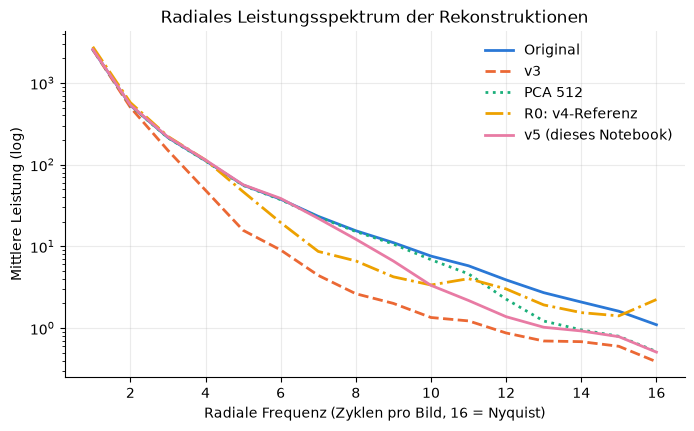

In [21]:
curves = [
    ("Original", original["spectrum"], "#2a78d6", "-"),
    ("v3", results["v3 (32 Dim.)"]["spectrum"], "#eb6834", "--"),
    ("PCA 512", results["PCA 512"]["spectrum"], "#1baf7a", ":"),
    ("v5 (dieses Notebook)", results["v5 (dieses Notebook)"]["spectrum"], "#e87ba4", "-"),
]
if RUN_LABELS["R0"] in results:
    curves.insert(3, ("R0: v4-Referenz", results[RUN_LABELS["R0"]]["spectrum"], "#eda100", "-."))

fig, ax = plt.subplots(figsize=(8, 4.5))
for label, spectrum, color, style in curves:
    ax.plot(range(1, 17), spectrum[1:], label=label, color=color, linestyle=style, linewidth=2)
ax.set_yscale("log")
ax.set_xlabel("Radiale Frequenz (Zyklen pro Bild, 16 = Nyquist)")
ax.set_ylabel("Mittlere Leistung (log)")
ax.set_title("Radiales Leistungsspektrum der Rekonstruktionen")
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

## 5. Einbetten mit dem Encoder <a name="encode"></a>

In [22]:
# Beispielbilder kodieren
# v5: Das räumliche 8x8xC-Embedding wird für die Auswertung flach gemacht.
embeddings = encoder.predict(example_images, verbose=0).reshape(len(example_images), -1)

In [23]:
# Einige Beispiele der Embeddings (die ersten 5 von EMBEDDING_DIM Werten)
print(embeddings[:10, :5])


[[ 0.91309196 -1.3056246  -1.2193823  -0.45967436 -1.5004845 ]
 [ 2.928667   -2.4658914  -0.38315502  2.3798103   0.96887404]
 [ 1.7677802  -1.0127785   0.9956812   2.2423604  -1.588185  ]
 [ 0.85990924 -2.0380917  -0.78621924  1.4157314   0.2021787 ]
 [ 0.35727286  1.2837368  -0.70687896 -0.34764892 -3.5990148 ]
 [ 0.01465903 -0.32905442 -1.6048696   1.1105598  -1.8031114 ]
 [ 1.2535961  -1.0897241  -0.7946904  -1.295038   -1.381628  ]
 [-0.21090731  0.12197257 -0.32440588  0.07011865 -2.3685236 ]
 [-3.2143989   0.7623539  -0.20283811 -2.2165005  -3.1650069 ]
 [ 2.4988112  -2.308649   -1.0052258   2.483968    0.0722539 ]]


### 5a. Einen höherdimensionalen latenten Raum visualisieren

Mit `EMBEDDING_DIM = 256` lässt sich das rohe Embedding nicht mehr direkt als Streudiagramm darstellen; zwei beliebige von 256 Achsen zu plotten, wäre genauso wenig aussagekräftig wie zuvor. Stattdessen projizieren wir das gesamte Embedding **nur zur Visualisierung** auf 2D, mit zwei Standardverfahren:

- **PCA**: eine schnelle, lineare Projektion auf die 2 Richtungen mit der größten Varianz. Gut als Plausibilitätsprüfung, kann aber nichtlineare Clusterstrukturen verbergen.
- **t-SNE**: eine nichtlineare Projektion, die gezielt lokale Nachbarschaften zu erhalten versucht. Sie zeigt tatsächlich vorhandene Clusterstrukturen im Embedding deshalb viel besser, ist aber langsamer und erhält globale Abstände nicht.

Überlappen sich die Klassen selbst in der t-SNE-Projektion stark, ist das ein deutliches Zeichen, dass das Embedding selbst die Klassen schlecht trennt (und nicht nur ein Artefakt des 2D-Plots).

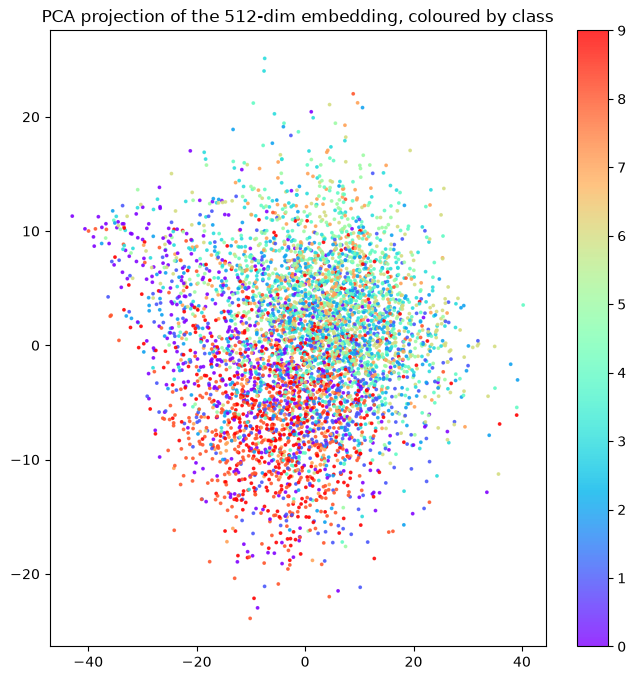

In [24]:
# PCA-Projektion des Embeddings, nach Klasse eingefärbt
pca = PCA(n_components=2)
embeddings_pca = pca.fit_transform(embeddings)

figsize = 8
plt.figure(figsize=(figsize, figsize))
scatter = plt.scatter(
    embeddings_pca[:, 0],
    embeddings_pca[:, 1],
    cmap="rainbow",
    c=example_labels,
    alpha=0.8,
    s=3,
)
plt.colorbar(scatter)
plt.title(f"PCA projection of the {EMBEDDING_DIM}-dim embedding, coloured by class")
plt.show()

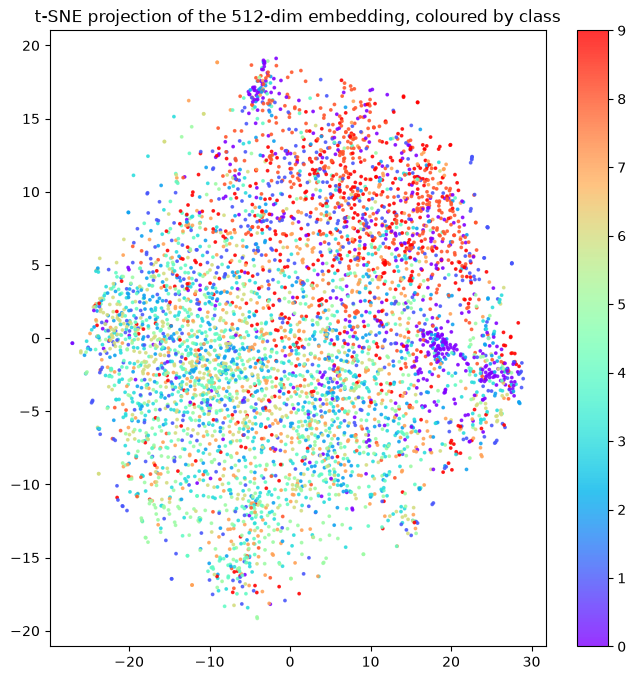

In [25]:
# t-SNE-Projektion des Embeddings, nach Klasse eingefärbt
tsne = TSNE(n_components=2, init="pca", perplexity=30, random_state=42)
embeddings_tsne = tsne.fit_transform(embeddings)

figsize = 8
plt.figure(figsize=(figsize, figsize))
scatter = plt.scatter(
    embeddings_tsne[:, 0],
    embeddings_tsne[:, 1],
    cmap="rainbow",
    c=example_labels,
    alpha=0.8,
    s=3,
)
plt.colorbar(scatter)
plt.title(f"t-SNE projection of the {EMBEDDING_DIM}-dim embedding, coloured by class")
plt.show()

### 5b. Klassentrennung quantifizieren: eine k-NN-Probe

Statt die Trennung nach Augenmaß zu beurteilen, ist es aussagekräftiger, das Embedding als Merkmale für einen einfachen Klassifikator zu verwenden und die Genauigkeit auf zurückgehaltenen Daten zu messen. Trägt das Embedding tatsächlich Klasseninformation, sollte selbst ein einfacher k-NN-Klassifikator das Raten (10 % bei 10 ausgeglichenen Klassen) deutlich schlagen. Schlägt er es kaum, ist das Embedding nicht klassentrennend, wie auch immer es im 2D-Plot aussieht, und kein Plot ändert daran etwas. Ist Klassentrennung tatsächlich das Ziel, muss sich das Trainingsziel selbst ändern (z. B. durch einen überwachten oder kontrastiven Loss).

Wir vergleichen drei Merkmalssätze auf demselben Train/Test-Split der 5000 Beispielbilder: rohe, flach gemachte Pixel, eine PCA in der Größe des Embeddings und das Embedding des Autoencoders. Die Probe trainiert nur auf 4000 Bildern, ihre Zahlen unterschätzen also, was die Merkmale auf dem vollen Trainingsset erreichen könnten.

In [26]:
labels_flat = example_labels.ravel()
pixels_flat = example_images.reshape(len(example_images), -1)

(
    emb_train, emb_test,
    pix_train, pix_test,
    y_train_knn, y_test_knn,
) = train_test_split(
    embeddings,
    pixels_flat,
    labels_flat,
    test_size=0.2,
    random_state=42,
    stratify=labels_flat,
)

pca_probe = PCA(n_components=EMBEDDING_DIM, random_state=42).fit(pix_train)
feature_sets = {
    "raw pixels": (pix_train, pix_test),
    f"{EMBEDDING_DIM}-dim PCA": (pca_probe.transform(pix_train), pca_probe.transform(pix_test)),
    f"{EMBEDDING_DIM}-dim AE embedding": (emb_train, emb_test),
}

for name, (features_train, features_test) in feature_sets.items():
    knn = KNeighborsClassifier(n_neighbors=5).fit(features_train, y_train_knn)
    accuracy = accuracy_score(y_test_knn, knn.predict(features_test))
    print(f"k-NN accuracy on {name}: {accuracy:.3f}")
print("random-guess baseline (10 classes): 0.100")


k-NN accuracy on raw pixels: 0.269
k-NN accuracy on 512-dim PCA: 0.273
k-NN accuracy on 512-dim AE embedding: 0.237
random-guess baseline (10 classes): 0.100


### Fazit: wie die Ergebnisse zu lesen sind

Alle Werte stammen vom Testset mit 10.000 Bildern, die k-NN-Probe von 5.000 Bildern.

| Lauf | Decoder | Loss | Dim. | Bilder | MSE | SSIM | Nyquist |
|---|---|---|---|---|---|---|---|
| R0: v4 nachgestellt | alt | MSE + VGG | 256 | 10.000 | 0,00907 | 0,663 | 0,901 |
| A2 | alt | MSE | 256 | 30.000 | 0,00842 | 0,629 | 0,176 |
| A1 | alt | L1 + SSIM | 256 | 30.000 | 0,00775 | 0,732 | 0,082 |
| R1 | neu | L1 + SSIM | 256 | 30.000 | 0,00296 | 0,867 | 0,008 |
| R2 | neu | R1 + 300 Schritte VGG und TV | 256 | 30.000 | 0,00292 | 0,867 | 0,008 |
| **v5 (dieses Notebook)** | **neu** | **L1 + SSIM** | **512** | **30.000** | **0,00216** | **0,903** | **0,007** |
| PCA 512 (Vergleich) | – | – | 512 | 45.000 | 0,00102 | 0,948 | 0,007 |

Im Original beträgt die Nyquist-Leistung 0,056.

- **Fraktale:** behoben. Die neue Architektur senkt die Nyquist-Leistung bei gleichem Loss um den Faktor 10 (A1 zu R1). Mit VGG lag sie beim alten Decoder rund fünfmal höher als ohne (A2 zu R0), wobei R0 weniger Bilder hatte.
- **Unschärfe:** deutlich verringert, nicht behoben. Über der mittleren Frequenz fehlen weiterhin Details.
- **Größter einzelner Hebel in v5:** die neue Architektur (A1 zu R1): MSE 62 % niedriger, SSIM +0,135, bei sonst gleichen Bedingungen.
- **Vergleich mit der PCA:** nicht geschlagen, die MSE liegt etwa doppelt so hoch. Das Kriterium aus dem Plan ist verfehlt.
- **Laplace-Schärfe:** R0 erreicht 0,0205, v5 nur 0,0150, obwohl R0 sichtbar schlechter ist. Die Kennzahl allein ist ungeeignet.
- **Klassifizierung:** schlechter als v3 (23,7 % gegenüber 33,8 %) und unter den rohen Pixeln (26,9 %). Das Ziel sieht die Labels weiterhin nie, und das räumliche Embedding ist wohl näher an den Pixeln.

**Nächste Schritte:**
1. **Länger trainieren** auf einer GPU, um zu prüfen, ob sich der Abstand zur PCA schließt.
2. **Adversarial-Term**, falls danach Schärfe weiterhin die Grenze ist.
3. **Überwachter Kopf oder kontrastives Lernen**, falls Klassentrennung das Ziel ist. Das wäre ein eigenes v6.